# 11.13 日学习笔记
## 1.softmax-concise
goal:通过深度学习框架的高级api实现softmax回归模型，

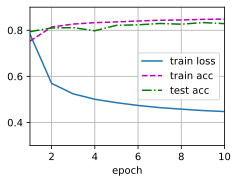

In [10]:
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
# 初始化模型参数
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
# 引入损失函数
loss = nn.CrossEntropyLoss(reduction='none')
# 优化算法
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
# 训练
num_epochs = 10
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)



## exercise
1.尝试调整超参数，比如批量大小、迭代周期数和学习率，并查看结果

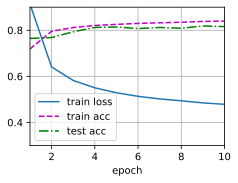

In [11]:
# 调整批量大小为512
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 512
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs = 10
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

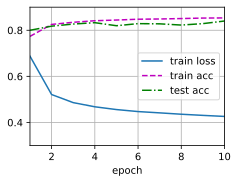

In [12]:
# 调整批量大小为128
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 128
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs = 10
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

KeyboardInterrupt: 

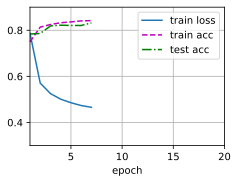

In [13]:
# 调整周期为20
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs = 20
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

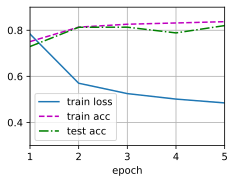

In [ ]:
# 调整周期为5
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs = 5
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

AssertionError: 0.6059911964416503

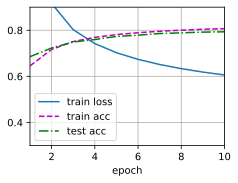

In [ ]:
# 调整学习率为0.01
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.01)
num_epochs = 10
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

AssertionError: 0.7377005358378093

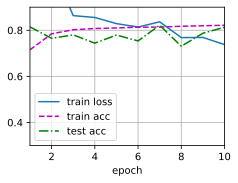

In [ ]:
# 调整学习率为0.5
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.5)
num_epochs = 10
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

2.增加迭代周期的数量。为什么测试精度会在一段时间后降低？我们怎么解决这个问题？

answer：

因为模型过拟合了
解决方案：
1.early-stopping 在测试表现开始恶化之前停止
2.weight decay 限制模型参数的范围
3.dropout 随机关闭部分神经元
4.data augmentation 对训练图片进行适当变换，增加训练数据多样性

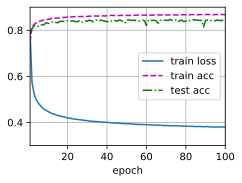

In [15]:
# 调整周期为300
import torch
from torch import nn
from d2l import torch as d2l
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs = 100
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

## 2.mlp(multiple-layer-preception)
### 2.exercise
1.计算pReLu激活函数的导数：

answer:

$$\frac{d}{dx}pReLu(x)=\begin{cases} 1 , x\gt 0 \\
 \\
\alpha , x\lt 0

\end{cases}$$

2.证明一个仅使用ReLu(或pReLu)的多层感知机构造了一个连续的分段线性函数

answer:

下用数学归纳法，对层数L进行归纳：

(1):L=1时
此时输出
$$y=\sigma(\mathbf{W}\vec{x}+b)$$
是分段线性函数
(2):假设命题对$L\lt k$成立，下证对$L=k$成立
记第$k-1$次输出的是$y_{k-1}(\vec{x})$是关于$\vec{x}$的分段线性函数，再做一次仿射变换得到
$$\sigma(\mathbf{W}_{k}y_{k-1}(\vec{x})+b_{k})$$
这是对一个分段线性函数再复合上一次ReLu函数，对于每一段
如果在这一段上不变号，复合后仍然线性  
如果在这一段上变号，复合后在两段上线性  
在每个变号点上取极限，得到变号点处连续  
因此是分段线性函数$\blacksquare$

3.证明$\tanh(x)=2sigmoid(2x)$

answer:

$$\begin{align}
\tanh (x) +1
&=\frac{1-\exp(-2x)}{1+\exp(-2x)} +1\\
&=\frac{2}{1+\exp(-2x)} \\
&=2sigmoid(2x)
\end{align}$$

4.假设我们有一个非线性单元，将它一次应用于一个小批量数据，这会导致什么样的问题？

answer:

我们使用小批量数据，是想加快参数更新的速度，也就是理论上结果等价于每次用一份数据更新  
但是如果这个非线性单元没办法让每个样本的输出都是独立于这个小批量的选择，那么会导致同一个样本在不同小批量的选取下产生不同的结果：
1.样本之间互相依赖
2.预测结果不稳定
3.破坏样本独立计算的性质
